Let's define the dampled harmonic oscillator

$$m \ddot x= - c \dot x - k (x-x_0) + f(t)$$
$$\iff \ddot x = - 2 \zeta \omega \dot x - \omega^2 (x - x_0) + \frac{f(t)}{m}$$

with $\omega = \frac{k}{m} \in \mathbb{R}^+$, $\zeta = \frac{c}{2 \sqrt{mk}} \in \mathbb{R}^+$ and $f(t) \sim \mathcal{N}[0, \sigma_f^2]$.

Let us make this non-linear by supposing that $M = \log m \sim \mathcal{N}[\bar{M}, \sigma_M^2]$.

This defines a state,

$$ z = [x, v, M]$$

transition mean function,

$$ z_{t}, t \to [x + v \Delta t, v + \frac{(f(t) -c v - k x)}{m} \Delta t, \bar M]$$

transition noise scale function,

$$ z_{t}, t \to [0, \sigma_f, \sigma_M]$$

observation mean function,

$$ z_{t}, t \to [x, 0, 0]$$

and observation noise scale function,

$$ z_{t}, t \to [\sigma_x, 0, 0]$$


In [1]:
import dataclasses
from functools import partial
from typing import NamedTuple, Union, TypeVar, Callable

import jax
import jax.numpy as jnp
import numpy as np
import pylab as plt
import tensorflow_probability.substrates.jax as tfp
from jaxns.internals.constraint_bijections import quick_unit, quick_unit_inverse

from essm_jax.essm import ExtendedStateSpaceModel
from essm_jax.jvp_op import JVPLinearOp
from essm_jax.pytee_utils import pytree_unravel

tfpd = tfp.distributions
FloatArray = Union[jax.Array, np.ndarray, float]

StateType = TypeVar("StateType")

ConstraintType = Callable[[StateType], StateType]


class State(NamedTuple):
    """
    State for a single timestep of the Kalman filter.
    """
    x: FloatArray | ConstraintType  # [n]
    v: FloatArray | ConstraintType  # [n]
    zeta: FloatArray | ConstraintType  # [n]
    omega: FloatArray | ConstraintType  # [n]


class Observation(NamedTuple):
    """
    Observables for a single timestep of the Kalman filter.
    """
    x: FloatArray  # [n]


n = 1  # Single dimension


@dataclasses.dataclass(eq=False)
class ExcitedDampedHarmonicOscillator:
    n: int = 1
    dt: float = 0.01
    x0: float = 0.
    sigma_f: float = 0.1
    sigma_x: float = 0.1
    sigma_zeta: float = 0.01
    sigma_omega: float = 0.01
    zeta0: float = 0.1
    omega0: float = 1.

    def __post_init__(self):
        example_state = State(
            x=jnp.ones((n,)),
            v=jnp.ones((n,)),
            zeta=jnp.ones((n,)),
            omega=jnp.ones((n,)),
        )

        example_observation = Observation(
            x=jnp.ones((n,))
        )

        self.state_ravel_fn, self.state_unravel_fn = pytree_unravel(example_state)
        self.obs_ravel_fn, self.obs_unravel_fn = pytree_unravel(example_observation)

        self.batched_state_ravel_fn = jax.vmap(self.state_ravel_fn)
        self.batched_state_unravel_fn = jax.vmap(self.state_unravel_fn)
        self.batched_obs_ravel_fn = jax.vmap(self.obs_ravel_fn)
        self.batched_obs_unravel_fn = jax.vmap(self.obs_unravel_fn)

        self.constrain_fns = State(
            x=partial(self.noop_constrain_fn),
            v=partial(self.noop_constrain_fn),
            zeta=partial(self.interval_constrain_fn, low=0., high=1.),
            omega=partial(self.interval_constrain_fn, low=0., high=2 * jnp.pi),
        )
        self.unconstrain_fns = State(
            x=partial(self.noop_unconstrain_fn),
            v=partial(self.noop_unconstrain_fn),
            zeta=partial(self.interval_unconstrain_fn, low=0., high=1.),
            omega=partial(self.interval_unconstrain_fn, low=0., high=2 * jnp.pi),
        )

    def error_prop(self, state0: State, constrained_state_sigma: State) -> State:
        # f = f(state0) + J.(state - state0)
        def unconstrain_fn(v: State) -> State:
            return State(*[unconstrain_fn(x) for x, unconstrain_fn in zip(v, self.unconstrain_fns)])

        Jop_bare = JVPLinearOp(unconstrain_fn)
        Jop = Jop_bare(state0)
        unconstrained_state_sigma = jnp.abs(Jop.matvec(constrained_state_sigma))
        return unconstrained_state_sigma

    def transition_fn(self, z: jax.Array, t: jax.Array, t_next: jax.Array,
                      *args) -> tfpd.MultivariateNormalLinearOperator:
        dt = t_next - t
        state: State = self.state_unravel_fn(z)
        state = State(*[constrain_fn(x) for x, constrain_fn in zip(state, self.constrain_fns)])
        c = 2. * state.zeta * state.omega
        k = state.omega ** 2
        a_mean = (-c * state.v - k * (state.x - self.x0))
        adt = a_mean * dt
        next_state_mean = State(
            x=state.x + state.v * dt + 0.5 * adt * dt,
            v=state.v + adt,
            zeta=state.zeta,
            omega=state.omega
        )
        ones = jnp.ones((self.n,))
        # Cov divided by var_f * dt**2 +  1e-6 I
        next_state_scale_constrained = State(
            x=self.sigma_f ** 2 * 0.25 * dt ** 4 * ones,
            v=self.sigma_f ** 2 * dt ** 2 * ones,
            zeta=dt * self.sigma_zeta ** 2 * ones,
            omega=dt * self.sigma_omega ** 2 * ones
        )
        next_state_scale = self.error_prop(
            state0=next_state_mean,
            constrained_state_sigma=next_state_scale_constrained
        )
        return tfpd.MultivariateNormalDiag(
            loc=self.state_ravel_fn(next_state_mean),
            scale_diag=self.state_ravel_fn(next_state_scale)
        )

    def observation_fn(self, z: jax.Array, t: jax.Array, *args) -> tfpd.MultivariateNormalLinearOperator:
        state: State = self.state_unravel_fn(z)
        state = State(*[constrain_fn(x) for x, constrain_fn in zip(state, self.constrain_fns)])
        obs_mean = Observation(
            x=state.x,
        )
        obs_scale = Observation(
            x=self.sigma_x * jnp.ones_like(state.x),
        )
        return tfpd.MultivariateNormalDiag(self.obs_ravel_fn(obs_mean), self.obs_ravel_fn(obs_scale))

    def noop_constrain_fn(self, unconstrained_var) -> jax.Array:
        return unconstrained_var

    def noop_unconstrain_fn(self, constrained_var) -> jax.Array:
        return constrained_var

    def interval_constrain_fn(self, unconstrained_var, low, high) -> jax.Array:
        interval_dist = tfpd.Uniform(low=low, high=high)
        u = quick_unit(unconstrained_var)
        return interval_dist.quantile(u)

    def interval_unconstrain_fn(self, constrained_var, low, high) -> jax.Array:
        interval_dist = tfpd.Uniform(low=low, high=high)
        u = interval_dist.cdf(constrained_var)
        return quick_unit_inverse(u)

    def positive_constrain_fn(self, unconstrained_var, mean) -> jax.Array:
        dist = tfpd.Exponential(rate=1. / mean)
        u = quick_unit(unconstrained_var)
        return dist.quantile(u)

    def positive_unconstrain_fn(self, constrained_var, mean) -> jax.Array:
        dist = tfpd.Exponential(rate=1. / mean)
        u = dist.cdf(constrained_var)
        return quick_unit_inverse(u)

    def normal_constrain_fn(self, unconstrained_var, mean, std) -> jax.Array:
        dist = tfpd.Normal(loc=mean, scale=std)
        u = quick_unit(unconstrained_var)
        return dist.quantile(u)

    def normal_unconstrain_fn(self, constrained_var, mean, std) -> jax.Array:
        dist = tfpd.Normal(loc=mean, scale=std)
        u = dist.cdf(constrained_var)
        return quick_unit_inverse(u)

    def create_initial_state_prior(self) -> tfpd.MultivariateNormalLinearOperator:
        initial_state = State(
            x=0. * jnp.ones((self.n,)),
            v=jnp.ones((self.n,)),
            zeta=self.zeta0 * jnp.ones((self.n,)),
            omega=self.omega0 * jnp.ones((self.n,)),
        )
        initial_state = State(*[unconstrain_fn(x) for x, unconstrain_fn in zip(initial_state, self.unconstrain_fns)])
        initial_state_scale = State(
            x=jnp.ones((self.n,)),
            v=jnp.ones((self.n,)),
            zeta=jnp.ones((self.n,)),
            omega=jnp.ones((self.n,)),
        )
        return tfpd.MultivariateNormalDiag(self.state_ravel_fn(initial_state), self.state_ravel_fn(initial_state_scale))

    def build_essm(self):
        return ExtendedStateSpaceModel(
            transition_fn=self.transition_fn,
            observation_fn=self.observation_fn,
            initial_state_prior=self.create_initial_state_prior(),
            more_data_than_params=False,
            dt=self.dt
        )


model = ExcitedDampedHarmonicOscillator(
    n=1,
    dt=0.1,
    x0=0.,
    sigma_f=0.5,
    sigma_x=1.,
    sigma_zeta=0.1,
    sigma_omega=0.1,
    zeta0=0.1,
    omega0=6.
)

T = int(10 / model.dt)

essm = model.build_essm()

samples = essm.sample(key=jax.random.PRNGKey(0), num_time=T)

filter_result = essm.forward_filter(observations=samples.observation)
smooth_result = essm.backward_smooth(filter_result=filter_result)

future_samples = essm.forward_simulate(key=jax.random.PRNGKey(0), num_time=int(5 / model.dt),
                                       filter_result=filter_result)
future_latent = model.batched_state_unravel_fn(future_samples.latent)

obs = model.batched_observables_unravel_fn(samples.observation)
state = model.batched_state_unravel_fn(samples.latent)
plt.plot(samples.t, state.x, label='x', c='r')
plt.plot(samples.t, state.v, label='v', c='b')
plt.plot(samples.t, state.zeta, label='zeta', c='purple')
plt.plot(samples.t, state.omega, label='omega', c='orange')
plt.plot(samples.t, obs.x, label='observed', alpha=0.5)

plt.plot(future_samples.t, future_latent.x, c='r')
plt.plot(future_samples.t, future_latent.v, c='b')
plt.plot(future_samples.t, future_latent.zeta, c='purple')
plt.plot(future_samples.t, future_latent.omega, c='orange')

plt.legend()
plt.show()

filter_latent = model.batched_state_unravel_fn(filter_result.filtered_mean)
filter_latent_std = model.batched_state_unravel_fn(jnp.sqrt(jax.vmap(jnp.diag)(filter_result.filtered_cov)))

plt.plot(filter_result.t, filter_latent.x, label='x', c='r')
plt.plot(filter_result.t, filter_latent.v, label='v', c='b')
plt.plot(filter_result.t, filter_latent.zeta, label='zeta', c='purple')
plt.fill_between(
    filter_result.t, filter_latent.zeta[:, 0] - filter_latent_std.zeta[:, 0],
                     filter_latent.zeta[:, 0] + filter_latent_std.zeta[:, 0],
    alpha=0.5
)
plt.plot(filter_result.t, filter_latent.omega, label='omega', c='orange')
plt.fill_between(
    filter_result.t, filter_latent.omega[:, 0] - filter_latent_std.omega[:, 0],
                     filter_latent.omega[:, 0] + filter_latent_std.omega[:, 0],
    alpha=0.5
)

/home/albert/miniconda3/envs/dsa_py/lib/python3.11/site-packages/jaxns/internals/mixed_precision.py:14: UserWarning: JAX x64 is not enabled. Setting it now. Check for errors.
  warnings.warn("JAX x64 is not enabled. Setting it now. Check for errors.")
INFO:2025-03-17 11:12:39,807:jax._src.xla_bridge:927: Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:2025-03-17 11:12:39,808:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:2025-03-17 11:12:39,810:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: c

TypeError: absolute requires ndarray or scalar arguments, got <class '__main__.State'> at position 0.

/tmp/ipykernel_1254184/980648694.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


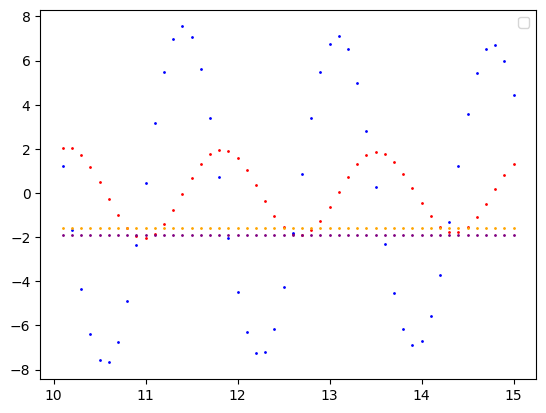

In [4]:

filter_state = essm.create_filter_state(filter_result=filter_result)
for _ in range(int(5 / model.dt)):
    filter_state = essm.incremental_predict(filter_state=filter_state)
    latent = model.state_unravel_fn(filter_state.filtered_mean)
    plt.scatter(filter_state.t, latent.x, c='r', s=1)
    plt.scatter(filter_state.t, latent.v, c='b', s=1)
    plt.scatter(filter_state.t, latent.zeta, c='purple', s=1)
    plt.scatter(filter_state.t, latent.omega, c='orange', s=1)

plt.legend()
plt.show()

